In [3]:
import pandas as pd
import matplotlib.pyplot as plt

In [4]:
   df = pd.read_csv("playgrounds.csv")
   df.head()

,_id,id,name,type,maintenance_responsibility,park,street,image,neighborhood,council_district,ward,tract,public_works_division,pli_division,police_zone,fire_zone,latitude,longitude
0,1,731501774,Able Long Playground,NaN,Parks - Western,Able Long Park,COAST AVE,https://tools.wprdc.org/images/pittsburgh/play...,Beechview,4,19,42003192000,5,19,6,4-28,40.408365,-80.028445
1,2,1461276747,Albert Graham Playground,NaN,Parks - Schenley,Albert Turk Graham Park,FORESIDE PL,https://tools.wprdc.org/images/pittsburgh/play...,Crawford-Roberts,6,3,42003030500,3,3,2,2-1,40.440519,-79.984137
2,3,1860709784,Alpine Playground,NaN,Parks - Northern,Alpine Gardens Park,ALPINE AVE,https://tools.wprdc.org/images/pittsburgh/play...,Central Northside,6,25,42003250300,1,25,1,1-21,40.457707,-80.012952
3,4,1770671485,Alton Playground,NaN,Parks - Western,Alton Park,ANDICK WAY,https://tools.wprdc.org/images/pittsburgh/play...,Beechview,4,19,42003191600,5,19,6,4-28,40.414137,-80.021605
4,5,18942817,Ammon Playground,NaN,Parks - Schenley,Ammon Park,MEMORY LN,https://tools.wprdc.org/images/pittsburgh/play...,Bedford Dwellings,6,5,42003050900,3,5,2,2-5,40.449037,-79.978064


In [5]:
print(df.shape)
print(df.columns)

(125, 18)
Index(['_id', 'id', 'name', 'type', 'maintenance_responsibility', 'park',
       'street', 'image', 'neighborhood', 'council_district', 'ward', 'tract',
       'public_works_division', 'pli_division', 'police_zone', 'fire_zone',
       'latitude', 'longitude'],
      dtype='object')


In [6]:
df = df[["name", "park", "neighborhood"]]
df.head()

,name,park,neighborhood
0,Able Long Playground,Able Long Park,Beechview
1,Albert Graham Playground,Albert Turk Graham Park,Crawford-Roberts
2,Alpine Playground,Alpine Gardens Park,Central Northside
3,Alton Playground,Alton Park,Beechview
4,Ammon Playground,Ammon Park,Bedford Dwellings


In [7]:
df.isna().sum()

name            0
park            2
neighborhood    0
dtype: int64

In [8]:
counts = df.groupby("neighborhood").size()
counts

neighborhood
Allegheny Center       4
Allentown              1
Banksville             1
Bedford Dwellings      1
Beechview              5
                      ..
Upper Lawrenceville    3
West End               1
West Oakland           1
Westwood               1
Windgap                1
Length: 68, dtype: int64

In [9]:
counts = counts.sort_values(ascending=False)
counts.head(10)

neighborhood
Squirrel Hill South    8
Beechview              5
South Side Slopes      5
Allegheny Center       4
Highland Park          4
Sheraden               4
Beltzhoover            4
Upper Lawrenceville    3
Mount Washington       3
Hazelwood              3
dtype: int64

In [10]:
df[df["neighborhood"] == "Squirrel Hill South"]

,name,park,neighborhood
17,Camp David Lawrence Playground,Schenley Park,Squirrel Hill South
25,Davis Playground,Davis Park,Squirrel Hill South
44,Frick Beechwood Playground,Frick Park,Squirrel Hill South
94,Schenley Anderson Playground,Schenley Park,Squirrel Hill South
95,Schenley Bartlett Playground,Schenley Park,Squirrel Hill South
96,Schenley Oval Playground,Schenley Park,Squirrel Hill South
97,Schenley Overlook Playground,Schenley Park,Squirrel Hill South
109,Vietnam Veteran's Playground,Schenley Park,Squirrel Hill South


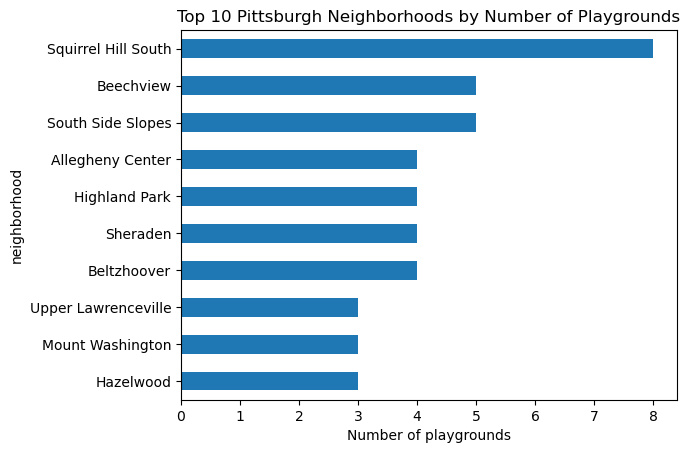

In [11]:
top10 = counts.head(10)
top10.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Number of playgrounds")
plt.title("Top 10 Pittsburgh Neighborhoods by Number of Playgrounds")
plt.show()

In [12]:
df["height_ft"] = 5
df.head()

,name,park,neighborhood,height_ft
0,Able Long Playground,Able Long Park,Beechview,5
1,Albert Graham Playground,Albert Turk Graham Park,Crawford-Roberts,5
2,Alpine Playground,Alpine Gardens Park,Central Northside,5
3,Alton Playground,Alton Park,Beechview,5
4,Ammon Playground,Ammon Park,Bedford Dwellings,5


In [13]:
height = df.groupby("neighborhood")["height_ft"].sum()
height = height.sort_values(ascending=False)
height.head(10)

neighborhood
Squirrel Hill South    40
Beechview              25
South Side Slopes      25
Allegheny Center       20
Highland Park          20
Sheraden               20
Beltzhoover            20
Upper Lawrenceville    15
Mount Washington       15
Hazelwood              15
Name: height_ft, dtype: int64

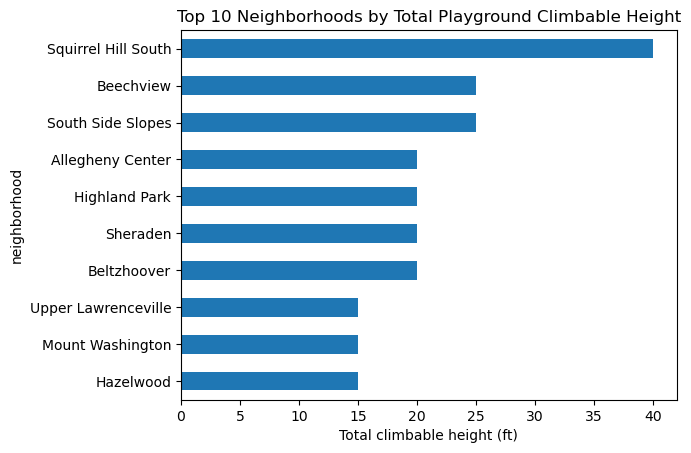

In [14]:
top10_height = height.head(10)
top10_height.plot(kind="barh")
plt.gca().invert_yaxis()
plt.xlabel("Total climbable height (ft)")
plt.title("Top 10 Neighborhoods by Total Playground Climbable Height")
plt.show()

In [15]:
height.to_csv("playground_height.csv")

# Conclusion

My sub-metric measures the total climbable height of playgrounds in each Pittsburgh neighborhood, using the City of Pittsburgh Playgrounds dataset from the WPRDC. The dataset lists 125 playgrounds across 68 neighborhoods, I calculated the height of every playground, which is 5 ft tall on average.

Based on this metric, the most climbable neighborhood is Squirrel Hill South, with 8 playgrounds and a total climbable height of 40 ft. Beechview and South Side Slopes tie for second place with 25 ft each. Squirrel Hill South comes out on top mainly because it contains Schenley Park, which alone has 6 playgrounds, plus one in Frick Park and one in Davis Park.